### <b>6차시 Seaborn과 분포 그래프 - set_theme · histplot · kdeplot · boxplot</b>

* <b>Seaborn</b>은 표(data)와 열 이름(x·y·hue)만 넘기면 그래프를 그려 준다. 그리는 곳은 Matplotlib의 Axes라서 <b>ax=</b>로 칸을 정하고 돌려받은 ax로 제목을 단다.
* <b>sns.set_theme</b>은 폰트 설정을 덮어쓴다. 그래서 테마를 정할 때 한글 폰트와 마이너스 설정을 함께 넘긴다.
* 분포는 <b>histplot</b>·<b>kdeplot</b>으로 모양을 보고, <b>boxplot</b>·<b>violinplot</b>으로 가운데와 퍼짐, 이상치를 집단끼리 비교한다.

* 맨 위 코드 셀은 <b>준비 셀</b>이다. 한글 폰트를 설치해 등록하고, 실습 데이터를 <b>data</b> 폴더에 내려받는다.
  * 내용은 고치지 않고 실행만 한다. 출력에 CSV 파일 이름 두 개가 보이면 끝난 것이다.
  * 세션이 끊겨도 입력한 코드는 남아 있다. 이어서 할 셀을 선택하고 <b>런타임 › 이전 셀 실행</b>을 누르면 준비 셀부터 다시 실행된다.
* 나머지 코드 칸은 강의를 따라 입력한다. 주석(#)은 입력하지 않아도 되고, 앞 셀과 비슷한 코드는 복사해 고친다.

In [1]:
# keep
# 나눔고딕 폰트를 설치한다
!apt-get -qq install -y fonts-nanum > /dev/null
# 실습 데이터를 data 폴더에 내려받는다
!mkdir -p data
!wget -q -nc -P data https://raw.githubusercontent.com/wonguwon/generate_lesson/feature/lesson-subagents/materials/matplotlib-seaborn/data/students.csv https://raw.githubusercontent.com/wonguwon/generate_lesson/feature/lesson-subagents/materials/matplotlib-seaborn/data/cafe_sales.csv
# 설치한 폰트를 Matplotlib에 등록한다
from matplotlib import font_manager
font_manager.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
# 내려받은 파일을 확인한다
!ls data

* 준비 셀 다음 셀에 <b>설정 셀</b>을 입력한다. 오늘부터 Seaborn을 쓰므로 6차시에서 이렇게 바꾸고, 7차시부터는 그대로 쓴다.
  * <b>import seaborn as sns</b>: Seaborn을 sns라는 별명으로 불러온다.
  * <b>sns.set_theme(...)</b>: Seaborn 테마를 정하면서 폰트와 마이너스 설정을 함께 넘긴다. 폰트는 준비 셀이 등록한 <b>NanumGothic</b>이다. 1차시의 plt.rcParams 두 줄이 이 한 줄로 바뀐다. 왜 함께 넘기는지는 1)에서 직접 확인한다.

In [2]:
# 표는 pandas, 그래프는 plt와 Seaborn으로 다룬다
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 테마와 한글 폰트를 함께 정한다
sns.set_theme(style='whitegrid', font='NanumGothic', rc={'axes.unicode_minus': False})

* 오늘은 학생 설문 파일 하나만 쓴다. 2차시와 같은 방법으로 읽는다.
  * <b>students</b>: 학생 300명의 생활 습관 설문(가상), 학생 1명 = 1행

In [3]:
# 학생 설문 CSV를 읽어 students에 담는다
students = pd.read_csv('data/students.csv')
# 표의 행과 열 수를 출력한다
print(students.shape)

(300, 12)


#### <b>1) set_theme와 한글 폰트를 함께 설정하고 첫 Seaborn 그래프</b>

* <b>sns.set_theme()</b>: Seaborn의 테마(배경·격자·글자 크기·색)를 한 번에 정한다.
  * 이때 폰트도 Seaborn 기본값('sans-serif')으로 다시 정한다. 앞에서 넣어 둔 한글 폰트가 덮어써진다.
* 직접 확인한다. 1차시 방식으로 폰트를 넣은 뒤 아무 인자 없이 set_theme을 부르고, 앞뒤의 폰트 설정을 출력한다.

In [4]:
# 1차시 방식으로 한글 폰트를 넣는다
plt.rcParams['font.family'] = 'NanumGothic'
# set_theme 전의 폰트 설정을 출력한다
print('set_theme 전:', plt.rcParams['font.family'])
# 인자 없이 테마를 정한다
sns.set_theme()
# set_theme 후의 폰트 설정을 출력한다
print('set_theme 후:', plt.rcParams['font.family'])

set_theme 전: ['NanumGothic']
set_theme 후: ['sans-serif']


* 폰트가 'sans-serif'로 바뀌었다. 이 상태에서 한글 제목을 단 그래프를 그려 본다.
  * <b>sns.histplot(data=표, x='열 이름')</b>: 표와 열 이름을 넘기면 그 열의 히스토그램을 그린다. 자세한 것은 2)에서 본다.
  * 아래 셀은 일부러 깨지게 만든 것이다. 한글이 네모(□)로 나오고, 'Glyph … missing from font(s) …' 경고가 찍힌다. 기본 폰트에 한글 글자가 없다는 뜻이다.

…/pylabtools.py:158: UserWarning: Glyph 51452 (\N{HANGUL SYLLABLE JU}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
…/pylabtools.py:158: UserWarning: Glyph 44036 (\N{HANGUL SYLLABLE GAN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
…/pylabtools.py:158: UserWarning: Glyph 44277 (\N{HANGUL SYLLABLE GONG}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
…/pylabtools.py:158: UserWarning: Glyph 48512 (\N{HANGUL SYLLABLE BU}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
…/pylabtools.py:158: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
…/pylabtools.py:158: UserWarning: Glyph 48516 (\N{HANGUL SYLLABLE BUN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
…/pylabtools.py:158: UserWarning: Glyph 54252 (\N{HANGUL SYLLABLE PO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


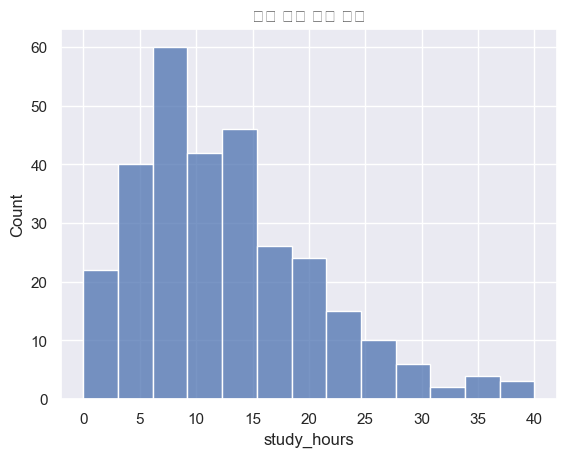

In [5]:
# Figure와 Axes를 만든다
fig, ax = plt.subplots()
# 공부 시간 히스토그램을 ax에 그린다
sns.histplot(data=students, x='study_hours', ax=ax)
# 한글 제목을 단다
ax.set_title('주간 공부 시간 분포')
# 그래프를 화면에 보여 준다
plt.show()

* 고치는 법: set_theme을 부를 때 <b>font=</b>에 한글 폰트 이름을, <b>rc=</b>에 마이너스 설정을 함께 넘긴다.
  * <b>style='whitegrid'</b>: 흰 바탕에 회색 격자. 기본값 'darkgrid'(회색 바탕)보다 보고서에 넣기 좋다.
  * <b>rc={'axes.unicode_minus': False}</b>: 1차시에서 본 마이너스 기호 설정을 테마에 함께 넣는다. 이 한 줄만 실행해도 폰트와 마이너스가 모두 맞춰진다.
* 설정 셀과 같은 줄이다. <b>sns.set_theme()</b>을 인자 없이 불러 글자가 깨지면 설정 셀을 다시 실행한다. 세션을 다시 시작했다면 준비 셀부터 실행한다.

In [6]:
# 폰트와 마이너스 설정을 함께 넘겨 테마를 정한다
sns.set_theme(style='whitegrid', font='NanumGothic', rc={'axes.unicode_minus': False})
# 폰트와 마이너스 설정을 출력한다
print(plt.rcParams['font.family'], plt.rcParams['axes.unicode_minus'])

['NanumGothic'] False


* 같은 그래프를 다시 그린다. 이번에는 Seaborn과 Matplotlib이 어떻게 이어지는지 본다.
  * Seaborn도 Matplotlib의 <b>Axes</b>(칸) 위에 그린다. <b>ax=ax</b>로 그릴 칸을 정한다.
  * Seaborn 함수는 그린 칸(Axes)을 돌려준다. 받은 값이 우리가 만든 ax와 같은 것인지 <b>is</b>로 확인한다.
  * 제목·축 이름은 3차시처럼 <b>ax.set_title</b>·<b>ax.set_xlabel</b>·<b>ax.set_ylabel</b>로 단다.

True


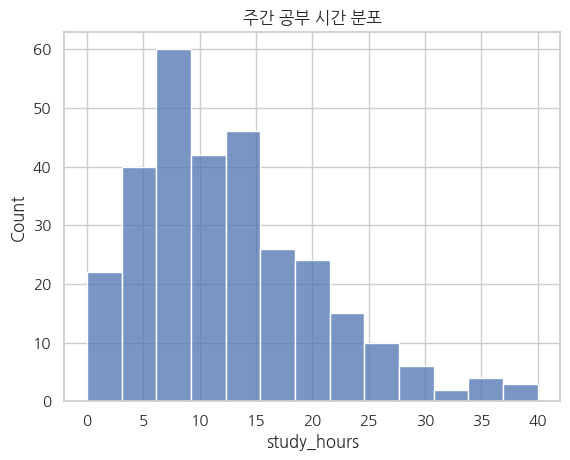

In [7]:
# Figure와 Axes를 만든다
fig, ax = plt.subplots()
# 히스토그램을 그리고 돌려받은 칸을 담는다
result = sns.histplot(data=students, x='study_hours', ax=ax)
# 돌려받은 칸이 ax와 같은 것인지 출력한다
print(result is ax)
# 한글 제목을 단다
ax.set_title('주간 공부 시간 분포')
# 그래프를 화면에 보여 준다
plt.show()

* 출력 True: Seaborn이 돌려준 것이 바로 우리가 만든 칸이다.
* 한글 제목이 제대로 나온다. 축 이름은 따로 달지 않았는데도 붙어 있다.
  * x축은 열 이름 'study_hours', y축은 'Count'(개수)다. Seaborn이 넘긴 열 이름으로 축 이름을 자동으로 단다.
  * 열 이름 그대로는 읽기 어려우므로 한글 축 이름으로 바꾼다.
* 앞 셀을 복사해 result와 print 줄을 빼고 축 이름 두 줄만 더한다.

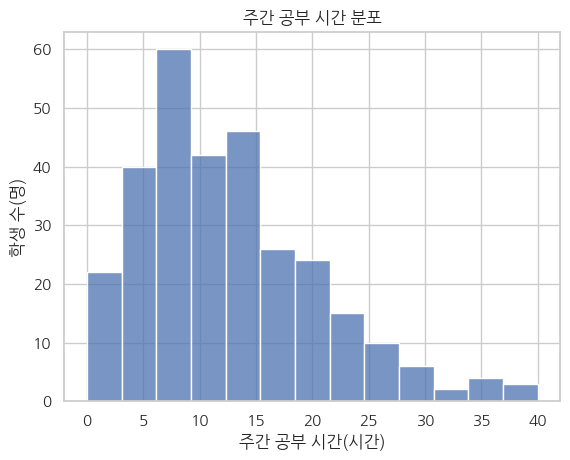

In [8]:
# 같은 그래프를 다시 그린다
fig, ax = plt.subplots()
sns.histplot(data=students, x='study_hours', ax=ax)
ax.set_title('주간 공부 시간 분포')
# x축과 y축 이름을 한글로 바꾼다
ax.set_xlabel('주간 공부 시간(시간)')
ax.set_ylabel('학생 수(명)')
# 그래프를 화면에 보여 준다
plt.show()

* 그래프에서 읽을 것
  * 막대가 13개다. 구간 수는 Seaborn이 데이터에 맞춰 정했다.
  * 6~9시간 구간이 60명으로 가장 높고, 오른쪽으로 40시간까지 꼬리가 길게 늘어진다. 몇몇 학생이 아주 오래 공부한다.
* Seaborn 함수의 공통 인자
  * <b>data</b>: 그릴 표(DataFrame)
  * <b>x</b>·<b>y</b>: 축에 놓을 열 이름(문자열)
  * <b>hue</b>: 색으로 나눌 열 이름. 3)에서 쓴다.
  * <b>ax</b>: 그릴 칸. 빼면 '지금 그리는 칸'에 그린다.

#### <b>2) 수면 시간 분포 histplot</b>

* 4차시에서 <b>ax.hist</b>로 수면 시간 히스토그램을 그렸다. 같은 그래프를 Seaborn으로 그려 나란히 비교한다.
  * 왼쪽(axes[0])은 4차시 방식: dropna로 빈 값을 뺀 sleep을 넘긴다.
  * 오른쪽(axes[1])은 Seaborn: 표와 열 이름만 넘긴다. 빈 값은 Seaborn이 알아서 뺀다.
  * 5차시의 subplots 칸을 Seaborn에서는 <b>ax=axes[1]</b>처럼 넘긴다.
  * 구간 수를 4차시와 똑같이 <b>bins=20</b>으로 맞춘다.

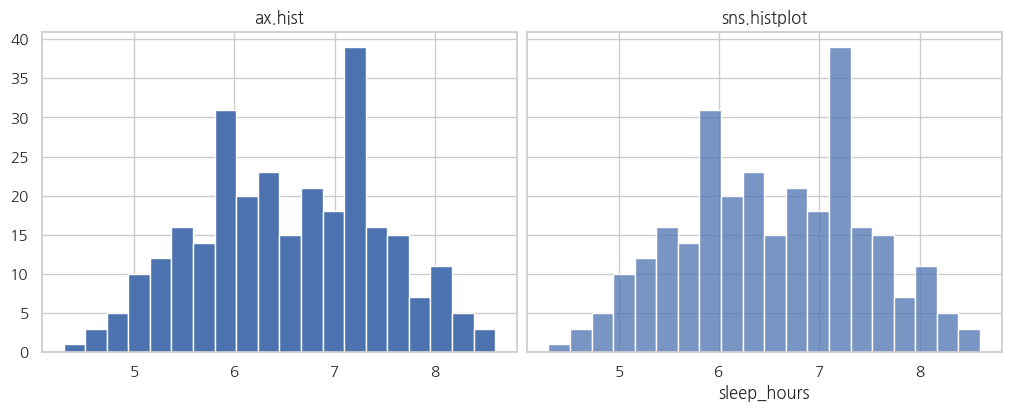

In [9]:
# 빈 값을 뺀 수면 시간을 sleep에 담는다
sleep = students['sleep_hours'].dropna()

# y축을 함께 쓰는 1행 2열 칸을 만든다
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True, layout='constrained')
# 왼쪽 칸에 ax.hist로 구간 20개를 그린다
axes[0].hist(sleep, bins=20)
# 왼쪽 칸의 제목을 단다
axes[0].set_title('ax.hist')
# 오른쪽 칸에 Seaborn으로 구간 20개를 그린다
sns.histplot(data=students, x='sleep_hours', bins=20, ax=axes[1])
# 오른쪽 칸의 제목을 단다
axes[1].set_title('sns.histplot')
# 그래프를 화면에 보여 준다
plt.show()

* 두 그래프의 막대 모양이 같다. 가장 높은 막대는 둘 다 7.10~7.31시간, 39명이다.
* 다른 점
  * Seaborn은 dropna 없이도 빈 값 15개를 빼고 285명을 그린다.
  * Seaborn은 x축 이름(sleep_hours)과 y축 이름(Count)을 자동으로 단다.
  * 막대 색과 테두리는 set_theme 테마를 따른다.
* 막대 높이의 합이 285인지 직접 더해 본다. <b>ax.patches</b>는 칸에 그려진 막대 목록이다.
  * <b>sum(p.get_height() for p in ax.patches)</b>: 막대를 하나씩 꺼내 높이(get_height)를 더한다. 5차시 리스트 문법에서 대괄호만 뺀 모양이다.
  * <b>plt.close(fig)</b>: 막대 높이 합만 보려고 그린 그림이라, 화면에 표시하지 않도록 닫는다.

In [10]:
# Figure와 Axes를 만든다
fig, ax = plt.subplots()
# 수면 시간 히스토그램을 구간 20개로 그린다
sns.histplot(data=students, x='sleep_hours', bins=20, ax=ax)
# 막대 높이를 모두 더해 출력한다
print(sum(p.get_height() for p in ax.patches))
# 화면에 나오지 않게 그림을 닫는다
plt.close(fig)

285


* bins를 빼면 Seaborn은 데이터에 맞춰 구간 수를 정한다. ax.hist의 기본 10개와 다르다.
* <b>kde=True</b>: 히스토그램 위에 막대를 매끄럽게 이은 곡선을 함께 그린다.
  * 이 곡선을 <b>밀도 곡선</b>(KDE)이라고 한다. 막대 높이에 맞춰 그려지므로 곡선 꼭대기가 막대 근처에 온다.

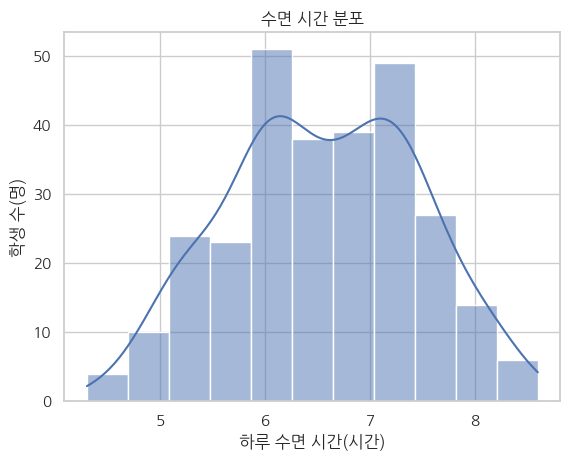

In [11]:
# Figure와 Axes를 만든다
fig, ax = plt.subplots()
# 히스토그램에 밀도 곡선을 얹어 그린다
sns.histplot(data=students, x='sleep_hours', kde=True, ax=ax)
# 제목과 축 이름을 단다
ax.set_title('수면 시간 분포')
ax.set_xlabel('하루 수면 시간(시간)')
ax.set_ylabel('학생 수(명)')
# 그래프를 화면에 보여 준다
plt.show()

* 막대가 11개로 나뉘었고, 가장 높은 막대는 5.86~6.25시간(51명)이다. bins=20일 때와 가장 높은 구간이 다르다.
  * 4차시에서 본 것처럼 구간을 어떻게 자르느냐에 따라 막대 모양이 달라진다.
* 곡선은 구간 경계에 덜 흔들린다. 6시간과 7시간 근처가 조금 높고, 양 끝으로 내려가는 종 모양에 가깝다.
* <b>sns.kdeplot</b>: 막대 없이 밀도 곡선만 그린다.
  * y축은 'Density'(밀도)다. 곡선 아래 넓이를 모두 더하면 1이 되도록 높이를 맞춘다.
  * 그래서 y축 숫자는 학생 수가 아니다. 어디가 높고 낮은지, 모양을 읽는다.

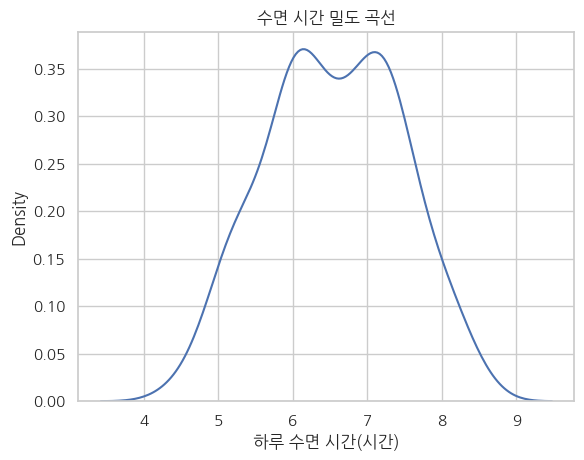

In [12]:
# Figure와 Axes를 만든다
fig, ax = plt.subplots()
# 수면 시간 밀도 곡선을 그린다
sns.kdeplot(data=students, x='sleep_hours', ax=ax)
# 제목과 x축 이름을 단다
ax.set_title('수면 시간 밀도 곡선')
ax.set_xlabel('하루 수면 시간(시간)')
# 그래프를 화면에 보여 준다
plt.show()

* 곡선은 데이터 범위(4.3~8.6시간)보다 조금 더 넓게 3.4~9.5시간까지 그려진다. 매끄럽게 잇느라 끝을 조금 번지게 그리기 때문이다.
* 히스토그램은 개수를 정확히 세고, 밀도 곡선은 모양을 매끄럽게 보여 준다. 함께 보면 둘의 약점이 서로 보완된다.

#### <b>3) 주거 형태별 통학 시간 분포 겹쳐 보기</b>

* <b>hue='housing'</b>: housing 열의 값(기숙사·자취·통학)마다 색을 나눠 그린다.
  * 2차시에서는 groupby로 집단을 나눴다. Seaborn은 열 이름 하나로 나누고, 색과 범례까지 붙인다.
  * 범례 제목은 열 이름 그대로 'housing'이다.

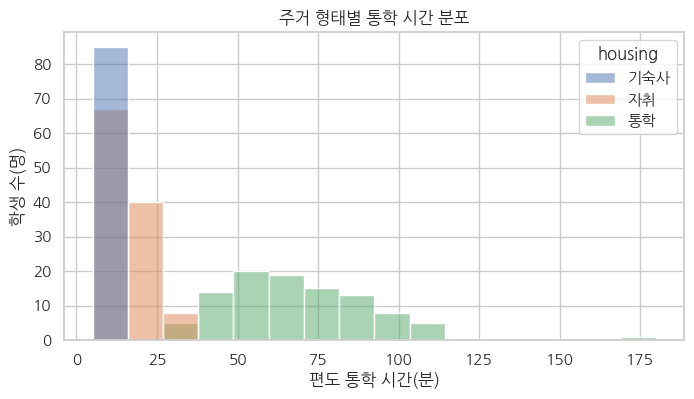

In [13]:
# 가로로 긴 Figure와 Axes를 만든다
fig, ax = plt.subplots(figsize=(8, 4))
# 주거 형태별로 색을 나눠 히스토그램을 그린다
sns.histplot(data=students, x='commute_minutes', hue='housing', ax=ax)
# 제목과 축 이름을 단다
ax.set_title('주거 형태별 통학 시간 분포')
ax.set_xlabel('편도 통학 시간(분)')
ax.set_ylabel('학생 수(명)')
# 그래프를 화면에 보여 준다
plt.show()

* 그래프에서 읽을 것
  * 기숙사 85명은 모두 첫 구간(5~16분)에 있다. 자취는 첫 세 구간(67·40·8명), 통학은 30분 이후로 넓게 퍼진다.
  * 오른쪽 끝 180분 근처에 통학 막대 하나(1명)가 홀로 떨어져 있다. 2차시에서 찾은 S037이다.
  * 첫 구간처럼 색이 겹치는 곳은 섞인 색으로 보여 읽기 어렵다.
* <b>multiple</b>: 집단 막대가 같은 구간에 모일 때 어떻게 놓을지 정한다.
  * <b>'layer'</b>(기본): 반투명하게 겹쳐 놓는다.
  * <b>'stack'</b>: 위로 쌓는다. 막대 전체 높이가 그 구간의 전체 학생 수다.
  * <b>'dodge'</b>: 옆으로 나란히 놓는다.
* 세 가지를 1×3 칸에 나란히 그려 비교한다.

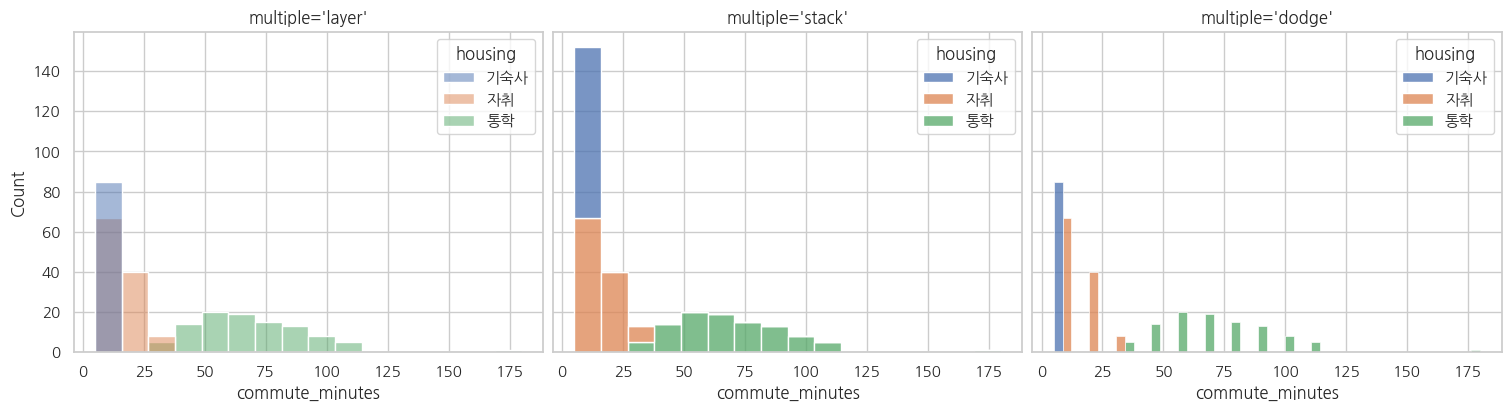

In [14]:
# y축을 함께 쓰는 1행 3열 칸을 만든다
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True, layout='constrained')
# 왼쪽 칸은 막대를 겹쳐 그리고 제목을 단다
sns.histplot(data=students, x='commute_minutes', hue='housing', multiple='layer', ax=axes[0])
axes[0].set_title("multiple='layer'")
# 가운데 칸은 막대를 쌓아 그리고 제목을 단다
sns.histplot(data=students, x='commute_minutes', hue='housing', multiple='stack', ax=axes[1])
axes[1].set_title("multiple='stack'")
# 오른쪽 칸은 막대를 나란히 그리고 제목을 단다
sns.histplot(data=students, x='commute_minutes', hue='housing', multiple='dodge', ax=axes[2])
axes[2].set_title("multiple='dodge'")
# 그래프를 화면에 보여 준다
plt.show()

* 'stack'의 첫 막대는 152명(기숙사 85 + 자취 67)이다. 구간 전체 인원은 잘 보이지만 위에 쌓인 집단의 모양은 읽기 어렵다.
* 'dodge'는 막대가 가늘어지지만 같은 구간의 집단끼리 높이를 바로 비교할 수 있다.
* 집단별 모양을 겹쳐 보는 데는 막대보다 곡선이 깔끔하다. kdeplot에도 hue를 쓴다.
  * 왼쪽은 기본값, 오른쪽은 <b>cut=0</b>을 넣었다. cut=0은 곡선을 데이터가 있는 범위에서 자른다.

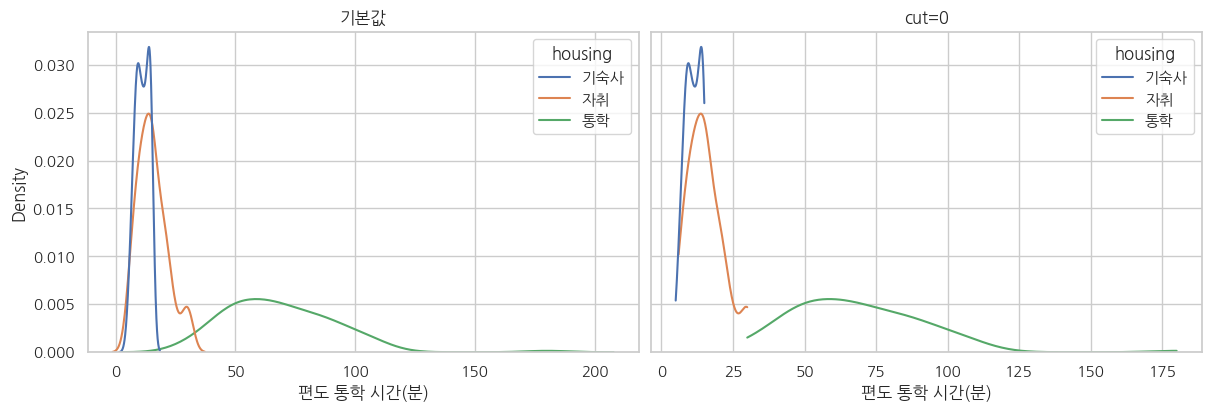

In [15]:
# y축을 함께 쓰는 1행 2열 칸을 만든다
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True, layout='constrained')
# 왼쪽 칸은 기본값으로 그리고 제목을 단다
sns.kdeplot(data=students, x='commute_minutes', hue='housing', ax=axes[0])
axes[0].set_title('기본값')
# 오른쪽 칸은 cut=0으로 그리고 제목을 단다
sns.kdeplot(data=students, x='commute_minutes', hue='housing', cut=0, ax=axes[1])
axes[1].set_title('cut=0')
# 두 칸의 x축 이름을 단다
axes[0].set_xlabel('편도 통학 시간(분)')
axes[1].set_xlabel('편도 통학 시간(분)')
# 그래프를 화면에 보여 준다
plt.show()

* 기본값(왼쪽)은 자취 곡선이 0분 아래까지 내려간다. 통학 시간이 음수일 수는 없으므로, 끝을 번지게 그린 탓이다.
  * cut=0(오른쪽)은 곡선이 실제 최솟값·최댓값에서 끝난다. 값에 0 같은 경계가 있는 열은 cut=0으로 그린다.
* 그래프에서 읽을 것
  * 기숙사·자취 곡선은 5~30분 안에서 높고 좁게 솟는다. 통학 곡선은 60분 근처를 꼭대기로 낮고 넓게 퍼진다.
  * 통학 곡선은 125분 뒤로 바닥에 붙은 채 180분까지 이어진다. S037 한 명 때문이다.
* hue로 나누면 세 곡선을 따로 1로 맞추지 않고, 세 곡선의 넓이를 합쳐 1이 되게 나눈다. 학생이 많은 집단일수록 곡선 넓이가 크다.

#### <b>4) 전공별 공부 시간 박스플롯과 바이올린 플롯</b>

* <b>박스플롯</b>(상자 그림)은 분포를 다섯 가지 값으로 요약한다.
  * <b>중앙값</b>: 값을 크기순으로 세웠을 때 한가운데 값. 상자 안의 가로선이다.
  * <b>사분위수</b>: 크기순으로 세운 값을 4등분하는 경계. 아래 25% 지점이 1사분위수(Q1), 위 25% 지점이 3사분위수(Q3)다. 상자의 아래·위 끝이다.
  * 상자에는 가운데 50% 학생이 들어 있다. 상자가 길수록 많이 퍼져 있다.
  * <b>수염</b>: 상자 끝에서 상자 길이의 1.5배 안에 있는 가장 먼 값까지 그은 선이다.
  * 수염 밖의 값은 점으로 따로 찍는다. 다른 값과 동떨어진 <b>이상치</b> 후보다.
* <b>sns.boxplot(data=표, x='범주 열', y='수치 열')</b>: 범주마다 상자를 하나씩 그린다.
  * 그대로 그리면 전공이 표에 처음 나온 순서로 놓인다. <b>order=</b>에 순서 리스트를 넘겨 중앙값이 큰 전공부터 놓는다.

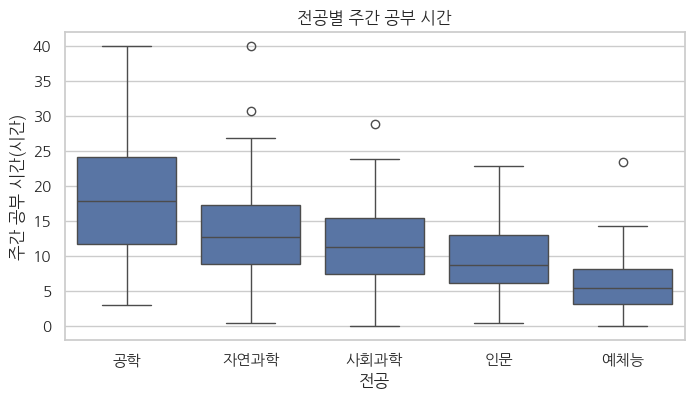

In [16]:
# 중앙값이 큰 전공부터 놓을 순서
major_order = ['공학', '자연과학', '사회과학', '인문', '예체능']

# 가로로 긴 Figure와 Axes를 만든다
fig, ax = plt.subplots(figsize=(8, 4))
# 전공별 공부 시간 박스플롯을 순서대로 그린다
sns.boxplot(data=students, x='major', y='study_hours', order=major_order, ax=ax)
# 제목과 축 이름을 단다
ax.set_title('전공별 주간 공부 시간')
ax.set_xlabel('전공')
ax.set_ylabel('주간 공부 시간(시간)')
# 그래프를 화면에 보여 준다
plt.show()

* 그래프에서 읽을 것
  * 중앙값(상자 안 가로선)이 공학 17.9 → 자연과학 12.7 → 사회과학 11.25 → 인문 8.7 → 예체능 5.45시간으로 내려간다. 4차시 평균 막대와 같은 순서다.
  * 공학 상자가 가장 길다. 공학 학생끼리도 공부 시간 차이가 크다.
  * 점은 4개다. 자연과학 30.7·40.0, 사회과학 28.8, 예체능 23.4시간
  * 공학에도 40시간 학생이 있지만 점이 아니다. 공학은 상자가 길어서 40시간이 수염 안에 들어간다. 이상치인지는 그 집단 안에서 정해진다.
* 평균 막대 하나로는 퍼짐과 이상치가 안 보였다. 박스플롯은 가운데·퍼짐·이상치를 한 번에 비교한다.

* 2차시에서 찾은 이상치 두 개를 박스플롯으로 다시 본다.
* 먼저 SNS 사용 시간. 상자를 가로로 눕히려면 x에 수치 열 하나만 넘긴다.
  * 점이 어디서부터 찍히는지 직접 계산한다. <b>quantile(0.25)</b>·<b>quantile(0.75)</b>는 1·3사분위수를 구한다.
  * 위쪽 경계 = Q3 + 1.5 × (Q3 - Q1). 이보다 큰 값이 점으로 찍힌다.

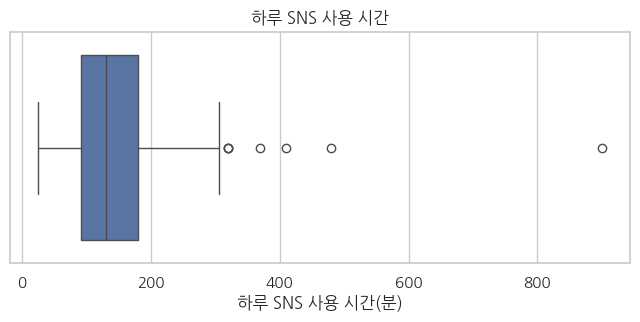

In [17]:
# 낮고 넓은 Figure와 Axes를 만든다
fig, ax = plt.subplots(figsize=(8, 3))
# SNS 사용 시간을 가로 박스플롯으로 그린다
sns.boxplot(data=students, x='sns_minutes', ax=ax)
# 제목과 x축 이름을 단다
ax.set_title('하루 SNS 사용 시간')
ax.set_xlabel('하루 SNS 사용 시간(분)')
# 그래프를 화면에 보여 준다
plt.show()

In [18]:
# 1사분위수와 3사분위수를 구한다
q1 = students['sns_minutes'].quantile(0.25)
q3 = students['sns_minutes'].quantile(0.75)
# 점이 찍히기 시작하는 위쪽 경계를 구한다
upper = q3 + 1.5 * (q3 - q1)
# 세 값을 출력한다
print(q1, q3, upper)
# 경계보다 큰 학생을 표로 본다
students[students['sns_minutes'] > upper][['student_id', 'sns_minutes']]

91.25 180.0 313.125


,student_id,sns_minutes
25,S026,900.0
103,S104,480.0
106,S107,320.0
129,S130,410.0
133,S134,370.0
206,S207,320.0
278,S279,320.0


* 위쪽 경계는 313.125분이고, 그보다 큰 학생이 7명이다.
  * 320분이 3명이라 점 하나로 겹쳐 보인다. 그래프에 보이는 점 자리는 다섯 곳이다.
  * 맨 오른쪽 홀로 떨어진 점이 2차시·4차시에서 본 S026(900분)이다.
* 점은 '확인해 볼 값'이라는 표시다. 오류인지 실제 값인지는 4차시에서처럼 원인을 확인한 뒤 정한다.
* 다음은 통학 시간을 주거 형태별로 본다.

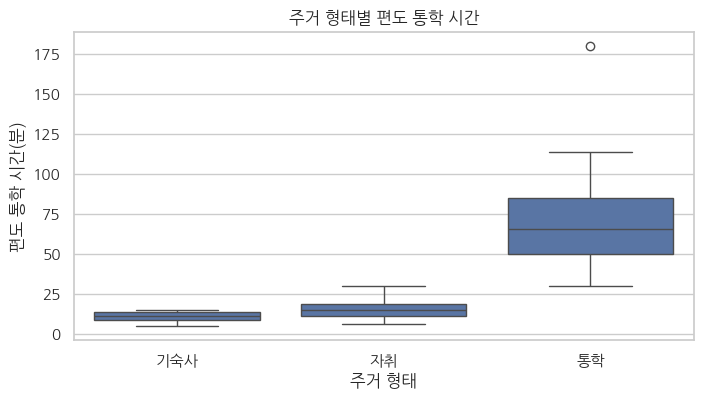

In [19]:
# 가로로 긴 Figure와 Axes를 만든다
fig, ax = plt.subplots(figsize=(8, 4))
# 주거 형태별 통학 시간 박스플롯을 그린다
sns.boxplot(data=students, x='housing', y='commute_minutes', ax=ax)
# 제목과 축 이름을 단다
ax.set_title('주거 형태별 편도 통학 시간')
ax.set_xlabel('주거 형태')
ax.set_ylabel('편도 통학 시간(분)')
# 그래프를 화면에 보여 준다
plt.show()

* 통학 상자 위에 점 하나가 있다. 180분, 2차시에서 찾은 S037이다.
  * 통학 집단의 위쪽 경계는 약 138분이다. 그다음으로 긴 114분은 수염 안에 들어간다.
* 기숙사·자취 상자는 바닥에 낮고 짧게, 통학 상자는 높고 길게 놓인다. 3)의 히스토그램에서 본 차이가 상자로 요약된다.

* <b>sns.violinplot</b>: 상자 대신 밀도 곡선을 좌우로 펼친 모양(바이올린)을 그린다.
  * 가운데 굵은 막대와 흰 짧은 가로선은 상자와 중앙값을 작게 그린 것이다.
  * 폭이 넓은 높이에 학생이 많다. 박스플롯은 다섯 값만 보여 주지만, 바이올린은 분포 모양까지 보여 준다.
  * <b>cut=0</b>: 3)의 kdeplot처럼, 넣지 않으면 0시간 아래까지 바이올린이 그려진다.
* 5차시의 1×2 칸에 박스플롯과 바이올린을 나란히 놓는다. 그리는 칸은 ax=axes[0], ax=axes[1]로 정한다.

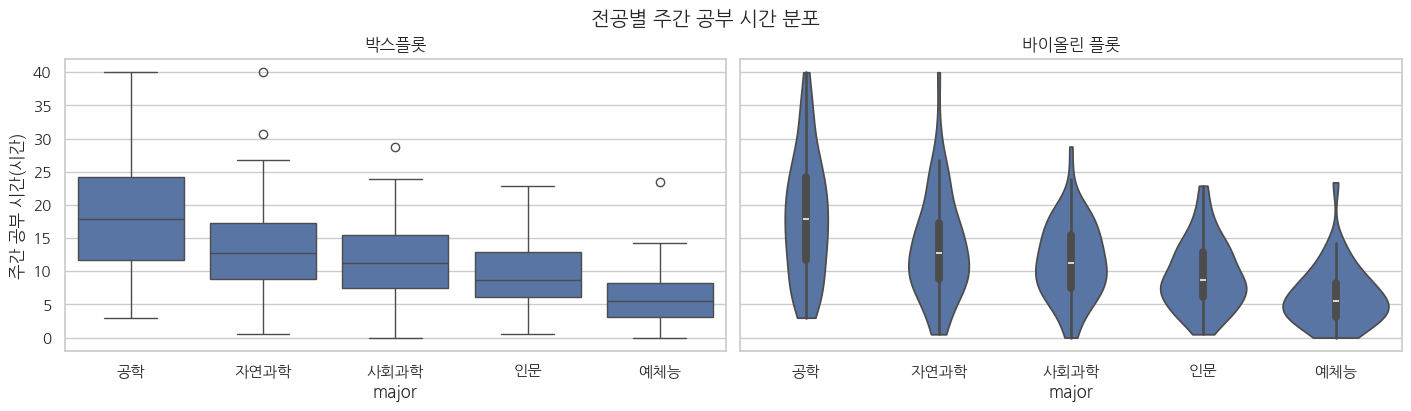

In [20]:
# y축을 함께 쓰는 1행 2열 칸을 만든다
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True, layout='constrained')
# 왼쪽 칸에 박스플롯을 그리고 제목을 단다
sns.boxplot(data=students, x='major', y='study_hours', order=major_order, ax=axes[0])
axes[0].set_title('박스플롯')
# 오른쪽 칸에 바이올린 플롯을 그리고 제목을 단다
sns.violinplot(data=students, x='major', y='study_hours', order=major_order, cut=0, ax=axes[1])
axes[1].set_title('바이올린 플롯')
# 왼쪽 칸의 y축 이름을 단다
axes[0].set_ylabel('주간 공부 시간(시간)')
# 칸 전체 위에 제목을 단다
fig.suptitle('전공별 주간 공부 시간 분포')
# 그래프를 화면에 보여 준다
plt.show()

* 그래프에서 읽을 것
  * 예체능 바이올린은 5시간 근처가 가장 넓고, 위로 가늘고 긴 꼬리가 있다. 박스플롯에서 점(23.4시간) 하나로 보이던 부분이다.
  * 공학 바이올린은 위로 40시간까지 길게 뻗는다. 상자가 가장 길었던 것과 같은 이야기다.
* 집단이 적고 요약만 필요하면 박스플롯, 분포 모양까지 보여 주려면 바이올린 플롯을 쓴다.
* 오늘 정리: 분포는 <b>모양·가운데·퍼짐</b>으로 읽는다. 히스토그램·밀도 곡선은 모양을, 박스플롯은 가운데와 퍼짐, 이상치를 보여 준다.